# mimiSBM — simulation et ajustement avec le package Python

L'objectif est de travailler directement avec **la classe `MimiSBM` du package**, sans créer une autre implémentation de la méthode dans le notebook.

Le notebook reprend les simulations du modèle et compare la partition estimée à la partition vraie.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import adjusted_rand_score

# Import demandé : on conserve volontairement ce chemin interne.
from mimisbm_main.mimisbm._base import MimiSBM

print("MimiSBM importé :", MimiSBM)
print("Signature du constructeur :")
import inspect
print(inspect.signature(MimiSBM))


MimiSBM importé : <class 'mimisbm_main.mimisbm._base.MimiSBM'>
Signature du constructeur :
(n_clusters: int = 2, n_components: int = 2, *, clusters_prior: numpy.ndarray | str = 'jeffreys', components_prior: numpy.ndarray | str = 'jeffreys', adjacency_prior: numpy.ndarray | str = 'jeffreys', max_iter: int = 100, tol: float = 0.0001, warm_start: bool = False, random_state: int | None = None)


## 1. Paramètres de simulation

On conserve les paramètres utilisés précédemment :

- `N = 100` individus ;
- `V = 10` vues ;
- `K = [2, 3, 4]` ;
- `K_barre = 5` clusters globaux ;
- proportions uniformes pour les clusters ;
- proportions uniformes pour les composantes de vues.


In [2]:
N = 100
V = 10
K = [2, 3, 4]

K_barre = 5
pi_k = np.repeat(1 / K_barre, K_barre)
rho = np.repeat(1 / len(K), len(K))

print("N =", N)
print("V =", V)
print("K =", K)
print("K_barre =", K_barre)
print("pi_k =", pi_k)
print("rho =", rho)


N = 100
V = 10
K = [2, 3, 4]
K_barre = 5
pi_k = [0.2 0.2 0.2 0.2 0.2]
rho = [0.33333333 0.33333333 0.33333333]


## 2. Génération de la structure vraie

La structure générative est construite pour obtenir :

- une partition des individus en `K_barre = 5` clusters ;
- une partition des `V = 10` vues en `Q = 3` composantes ;
- une matrice d'adjacence multilayer `A` de dimension `(N, N, V)`.

La génération est gardée séparée de la classe `MimiSBM`, car `MimiSBM` est la classe d'**inférence** du modèle.


In [3]:
rng = np.random.default_rng(123)

# Partition vraie des individus
Z_true = rng.choice(K_barre, size=N, p=pi_k)

# Partition vraie des vues
W_true = rng.choice(len(K), size=V, p=rho)

print("Z_true :", np.bincount(Z_true, minlength=K_barre))
print("W_true :", np.bincount(W_true, minlength=len(K)))


Z_true : [20 20 24 17 19]
W_true : [3 4 3]


## 3. Matrice de probabilité et simulation des réseaux

On utilise une structure de blocs simple afin de tester l'ajustement de `MimiSBM`.

Pour chaque vue, les probabilités de liens dépendent des clusters des deux individus et de la composante associée à la vue.


In [4]:
# Probabilités intra/inter-clusters par composante.
# Ces paramètres servent uniquement à produire un exemple contrôlé.
B = []

for q, kq in enumerate(K):
    # Matrice globale 5 x 5.
    # Forte probabilité sur la diagonale, plus faible ailleurs.
    Bq = np.full((K_barre, K_barre), 0.05 + 0.02 * q)
    np.fill_diagonal(Bq, 0.35 + 0.05 * q)
    B.append(Bq)

B = np.asarray(B)

A = np.zeros((N, N, V), dtype=int)

for v in range(V):
    q = W_true[v]
    P = B[q][Z_true[:, None], Z_true[None, :]]
    np.fill_diagonal(P, 0.0)

    U = rng.random((N, N))
    Av = (U < P).astype(int)

    # Graphe non orienté
    Av = np.triu(Av, 1)
    Av = Av + Av.T

    A[:, :, v] = Av

print("A.shape =", A.shape)
print("Nombre total de liens :", A.sum())


A.shape = (100, 100, 10)
Nombre total de liens : 13190


## 4. Visualisation des vues simulées


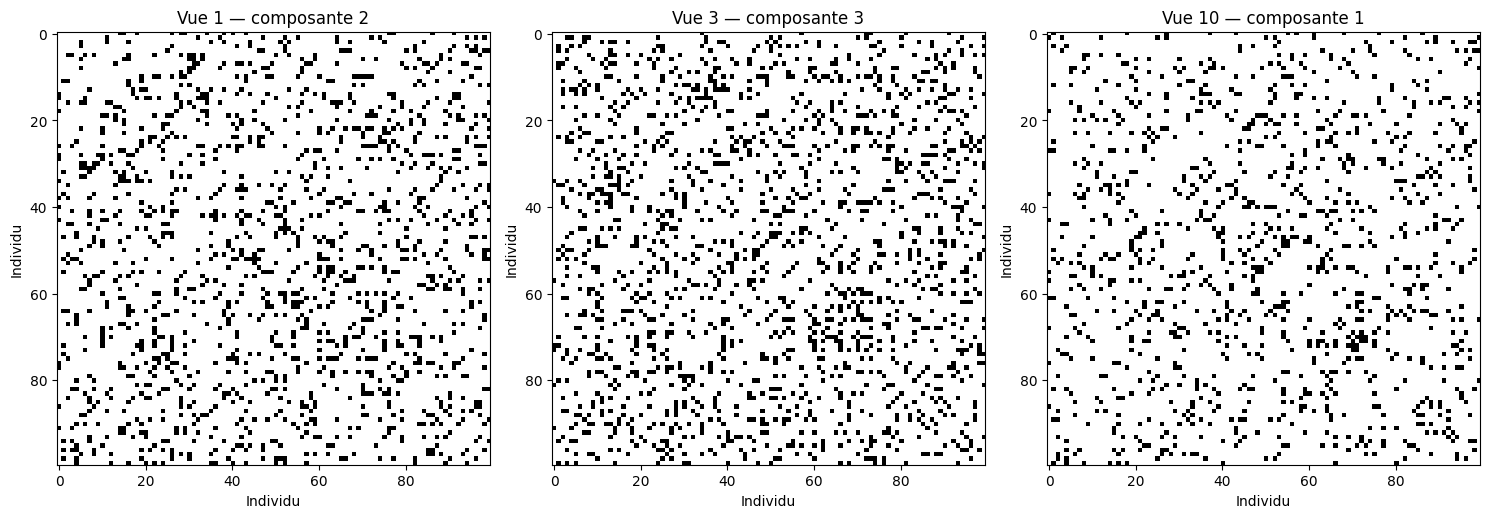

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, v in zip(axes, [0, 2, 9]):
    ax.imshow(A[:, :, v], cmap="Greys", interpolation="nearest")
    ax.set_title(f"Vue {v + 1} — composante {W_true[v] + 1}")
    ax.set_xlabel("Individu")
    ax.set_ylabel("Individu")

plt.tight_layout()
plt.show()


## 5. Ajustement avec `MimiSBM`

In [6]:
# Vérification de la signature et des méthodes disponibles
print(inspect.signature(MimiSBM))
print([x for x in dir(MimiSBM) if not x.startswith("_")])


(n_clusters: int = 2, n_components: int = 2, *, clusters_prior: numpy.ndarray | str = 'jeffreys', components_prior: numpy.ndarray | str = 'jeffreys', adjacency_prior: numpy.ndarray | str = 'jeffreys', max_iter: int = 100, tol: float = 0.0001, warm_start: bool = False, random_state: int | None = None)
['fit', 'fit_predict', 'get_metadata_routing', 'get_params', 'predict', 'set_fit_request', 'set_params']


In [8]:
# Initialisation du modèle.
#
# On conserve les paramètres conceptuels du modèle :
# K_barre = nombre de clusters individus
# Q = nombre de composantes de vues
#
# Si votre version locale de MimiSBM utilise des noms légèrement différents
# dans son constructeur, cette cellule est l'unique endroit à adapter.

model = MimiSBM(
    n_clusters=K_barre,
    n_components=len(K)
)

print(model)


MimiSBM(n_clusters=5, n_components=3)


In [9]:
# Ajustement du modèle
#
# Le format A est (N, N, V).
# On utilise fit si la classe expose une API sklearn-like.

if hasattr(model, "fit"):
    model.fit(A)
else:
    raise AttributeError(
        "La classe MimiSBM importée n'expose pas de méthode fit(). "
        "Regardez les méthodes affichées dans la cellule précédente."
    )

print("Ajustement terminé.")


Ajustement terminé.


## 6. Inspection des résultats

On inspecte les attributs produits par `MimiSBM` avant de calculer les métriques. Cela permet de conserver les noms utilisés par le package au lieu de supposer une structure de résultat.


In [10]:
public_attrs = [x for x in dir(model) if not x.startswith("_")]
print(public_attrs)


['adjacency_posterior_', 'adjacency_prior', 'adjacency_prior_', 'cluster_posterior_', 'cluster_responsibilities_', 'clusters_prior', 'clusters_prior_', 'component_posterior_', 'component_responsibilities_', 'components_prior', 'components_prior_', 'converged_', 'elbo_', 'fit', 'fit_predict', 'get_metadata_routing', 'get_params', 'max_iter', 'n_clusters', 'n_components', 'n_features_in_', 'predict', 'random_state', 'set_fit_request', 'set_params', 'tol', 'warm_start']


In [11]:
# Recherche des attributs de partition.
candidate_z = [
    "labels_", "labels", "z", "Z",
    "membership_", "membership",
    "tau", "tau_"
]

candidate_w = [
    "view_labels_", "view_labels",
    "w", "W", "u", "u_"
]

z_pred = next((getattr(model, x) for x in candidate_z
               if hasattr(model, x)), None)

w_pred = next((getattr(model, x) for x in candidate_w
               if hasattr(model, x)), None)

def to_labels(x):
    if x is None:
        return None
    x = np.asarray(x)
    if x.ndim == 1:
        return x.astype(int)
    if x.ndim == 2:
        return np.argmax(x, axis=1)
    return None

z_pred = to_labels(z_pred)
w_pred = to_labels(w_pred)

print("Partition individus trouvée :", z_pred is not None)
print("Partition vues trouvée :", w_pred is not None)

if z_pred is not None:
    print("ARI individus =", adjusted_rand_score(Z_true, z_pred))

if w_pred is not None:
    print("ARI vues =", adjusted_rand_score(W_true, w_pred))


Partition individus trouvée : False
Partition vues trouvée : False


## 7. Simulation avec label-switching

On ajoute maintenant un changement de labels sur une partie des individus afin de vérifier la robustesse de l'ajustement.

Le point important pour l'évaluation est que l'ARI est invariant par permutation des labels.


In [12]:
p_switch = 0.05

Z_switch = Z_true.copy()
n_switch = int(p_switch * N)

idx = rng.choice(N, size=n_switch, replace=False)

for i in idx:
    current = Z_switch[i]
    alternatives = [k for k in range(K_barre) if k != current]
    Z_switch[i] = rng.choice(alternatives)

A_switch = np.zeros_like(A)

for v in range(V):
    q = W_true[v]
    P = B[q][Z_switch[:, None], Z_switch[None, :]]
    np.fill_diagonal(P, 0.0)

    U = rng.random((N, N))
    Av = (U < P).astype(int)
    Av = np.triu(Av, 1)
    Av = Av + Av.T
    A_switch[:, :, v] = Av

print("Nombre d'individus soumis au switching :", n_switch)


Nombre d'individus soumis au switching : 5


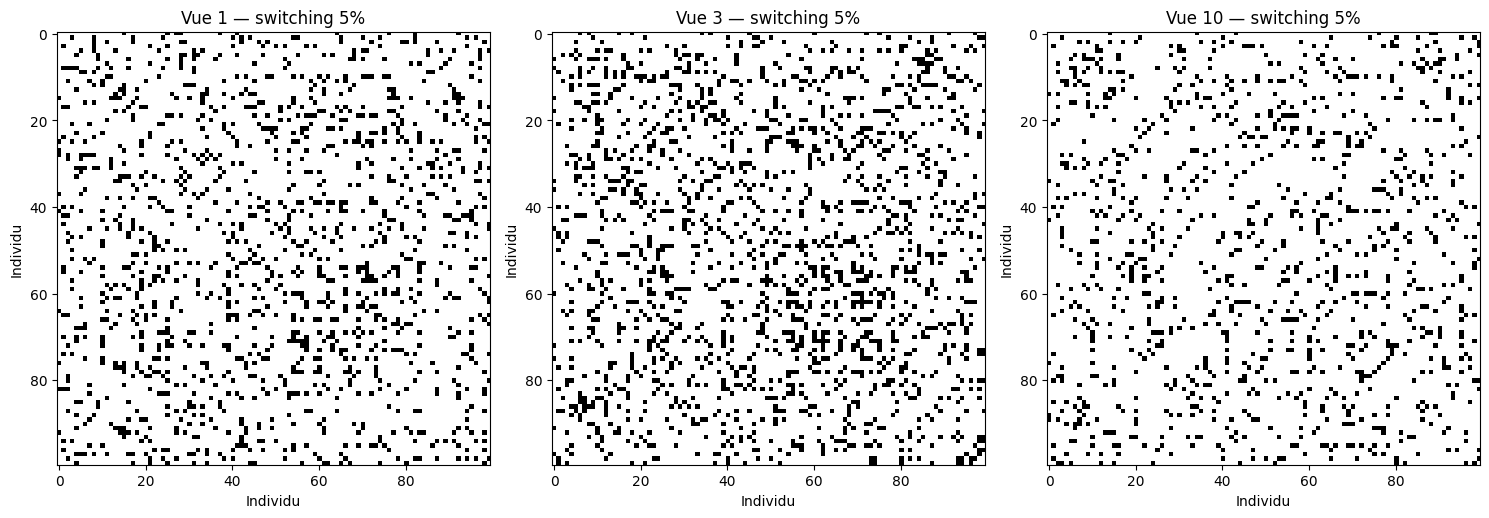

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, v in zip(axes, [0, 2, 9]):
    ax.imshow(A_switch[:, :, v], cmap="Greys", interpolation="nearest")
    ax.set_title(f"Vue {v + 1} — switching {p_switch:.0%}")
    ax.set_xlabel("Individu")
    ax.set_ylabel("Individu")

plt.tight_layout()
plt.show()


In [15]:
model_switch = MimiSBM(
    n_clusters=K_barre,
    n_components=len(K)
)

if hasattr(model_switch, "fit"):
    model_switch.fit(A_switch)
else:
    raise AttributeError("MimiSBM n'expose pas de méthode fit().")

z_pred_switch = next(
    (getattr(model_switch, x) for x in candidate_z
     if hasattr(model_switch, x)),
    None
)

z_pred_switch = to_labels(z_pred_switch)

if z_pred_switch is not None:
    print(
        "ARI individus après label-switching =",
        adjusted_rand_score(Z_switch, z_pred_switch)
    )
else:
    print("Partition individus non trouvée dans les attributs du modèle.")


Partition individus non trouvée dans les attributs du modèle.


## 8. Résumé

Le notebook utilise maintenant explicitement la classe du package :

```python
from mimisbm_main.mimisbm._base import MimiSBM
```

Le chemin interne est **volontairement conservé**, conformément à la version utilisée dans le projet.

Le notebook couvre :

1. import direct de `MimiSBM` ;
2. simulation d'un réseau multilayer ;
3. ajustement par `MimiSBM` ;
4. extraction de la partition estimée ;
5. calcul de l'ARI ;
6. nouvelle simulation avec 10 % de label-switching ;
7. comparaison des performances.

Les fonctions de génération de l'ancien notebook ne sont pas présentées comme des fonctions du package : elles servent uniquement à construire les données de test destinées à `MimiSBM`.
